## Causal vs non-Causal

In [1]:
#!pip install -U denoiser
#!pip install matplotlib
#! pip install torchaudio 2.1.0!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!

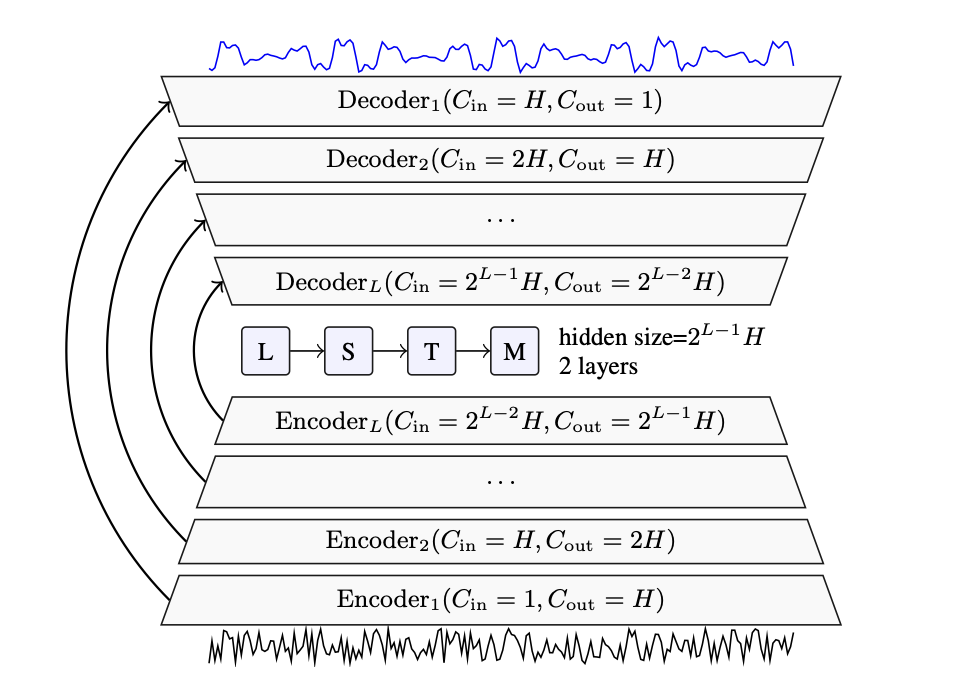

In [2]:
from IPython import display as disp
import torch
import torchaudio
from denoiser import pretrained
from denoiser.dsp import convert_audio
from scipy.signal import wiener, convolve
from scipy.special import sinc
import matplotlib.pyplot as plt
import numpy as np
import scipy
import matplotlib

In [ ]:
# Downloading a test file
#!wget https://facebookresearch.github.io/denoiser/audio/noisy/alex_noisy.mp3

## Causal DEMUCS

In [3]:
model = pretrained.dns64()
wav, sr = torchaudio.load('./alex_noisy.mp3',format="mp3")
wav = convert_audio(wav, sr, model.sample_rate, model.chin)

In [4]:

with torch.no_grad():
    causal_denoised = model(wav[None,:])[0]


In [5]:
disp.display(disp.Audio(wav.numpy(), rate=model.sample_rate))
disp.display(disp.Audio(causal_denoised.numpy(), rate=model.sample_rate))

In [6]:
wiener_denoised = wiener(wav.squeeze().numpy(), 7)
disp.display(disp.Audio(wav.numpy(), rate=sr))
disp.display(disp.Audio(wiener_denoised, rate=sr))

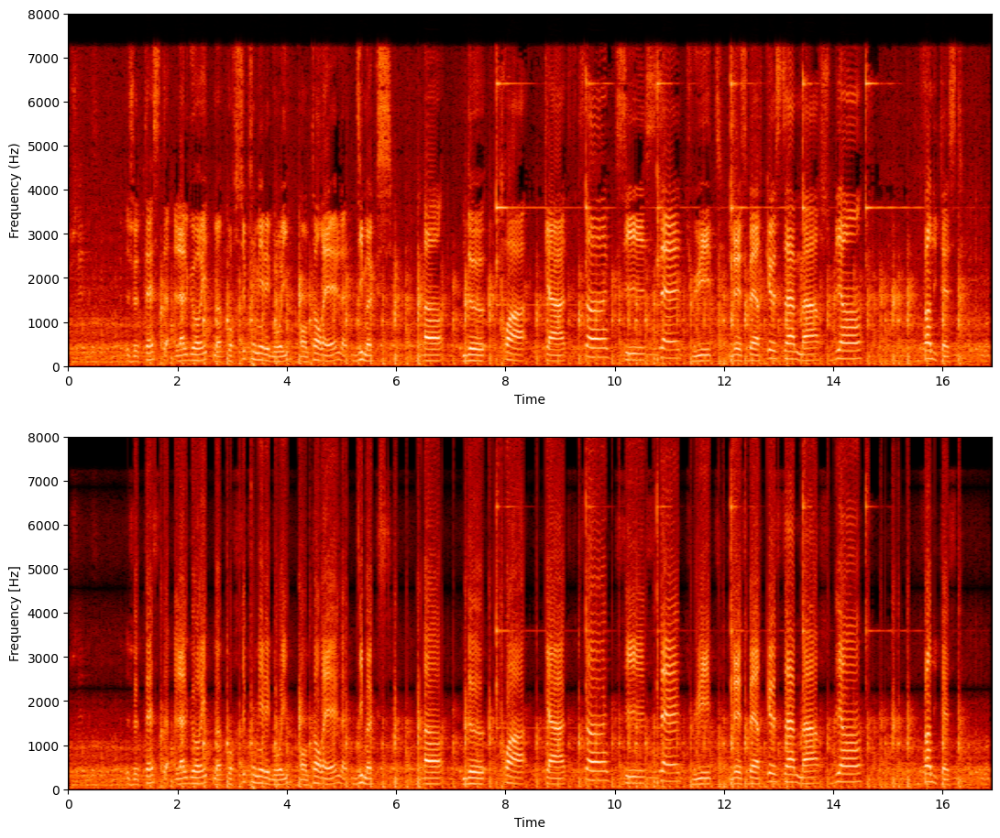

In [7]:
n_fft = 1024
window_size = n_fft
hop_size = 256
window = torch.hann_window(window_size)

def plot_specs(wav1, wav2):
    freqs1, ts1, spec1 = scipy.signal.stft(wav1, sr, nperseg=n_fft)
    freqs2, ts2, spec2 = scipy.signal.stft(wav2, sr, nperseg=n_fft)
    norm_factor = np.amax(np.abs(spec1))/np.amax(np.abs(spec2))
    spec2 = spec2 * norm_factor

    fig, (ax11,ax21) = plt.subplots(2,1,figsize=(13,11))

    ax11.pcolormesh(ts1, freqs1, np.log(np.abs(spec1) + 1e-6),  shading='gouraud', cmap=matplotlib.colormaps['gist_heat'])
    ax11.set_ylabel('Frequency (Hz)')
    ax11.set_xlabel('Time')

    im2=ax21.pcolormesh(ts2, freqs2, np.log(np.abs(spec2) + 1e-6),  shading='gouraud', cmap=matplotlib.colormaps['gist_heat'])
    ax21.set_ylabel('Frequency [Hz]')
    ax21.set_xlabel('Time')

    plt.show()

def visualize_audio(wav, sr):
    # Average all channels
    if wav.dim() == 2:
        # Any to mono audio convertion
        wav = wav.mean(dim=0)

    plt.figure(figsize=(20, 5))
    plt.plot(wav, alpha=.7, c='green')
    plt.grid()
    plt.xlabel('Time', size=20)
    plt.ylabel('Amplitude', size=20)
    plt.show()

    disp.display(disp.Audio(wav, rate=sr))

plot_specs(wav.squeeze().numpy(), wiener_denoised.squeeze())


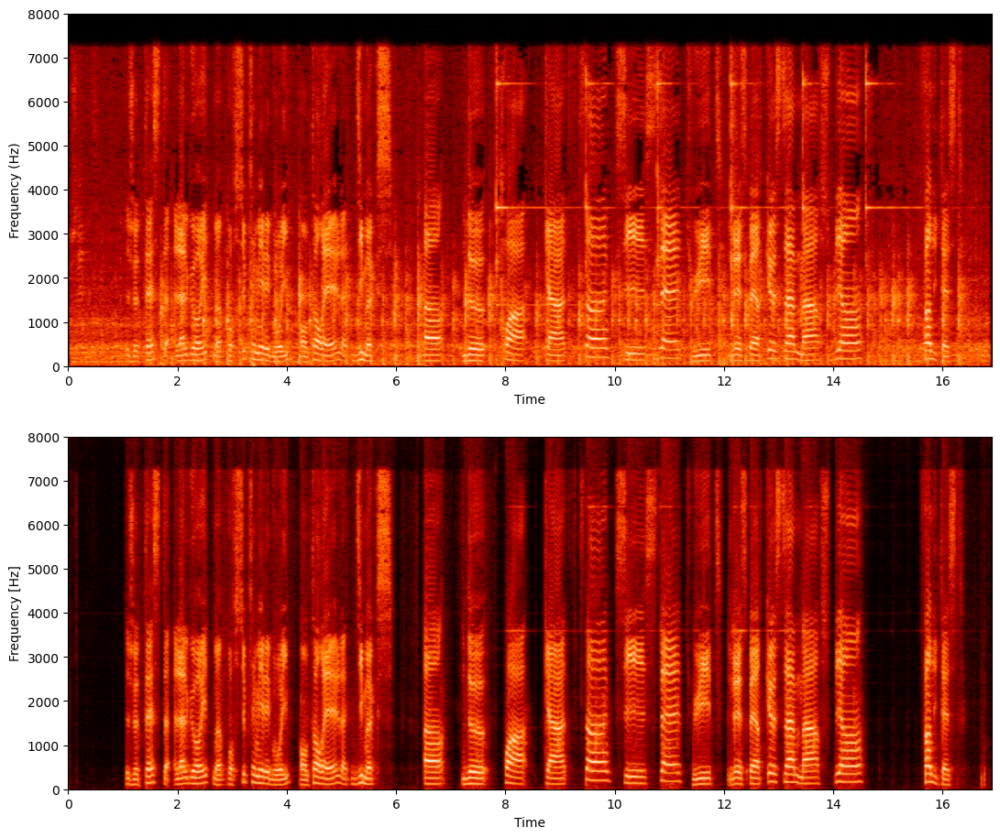

In [8]:
plot_specs(wav.squeeze().numpy(), causal_denoised.squeeze())

One of the constructions of rectangular low- and hi-pass filters comes from the usage of the sinc function.

## Non-Causal DEMUCS

In [9]:
model_nc = pretrained.valentini_nc()

with torch.no_grad():
    nc_denoised = model_nc(wav[None,:])[0]
disp.display(disp.Audio(wav.numpy(), rate=model.sample_rate))
disp.display(disp.Audio(nc_denoised.numpy(), rate=model.sample_rate))

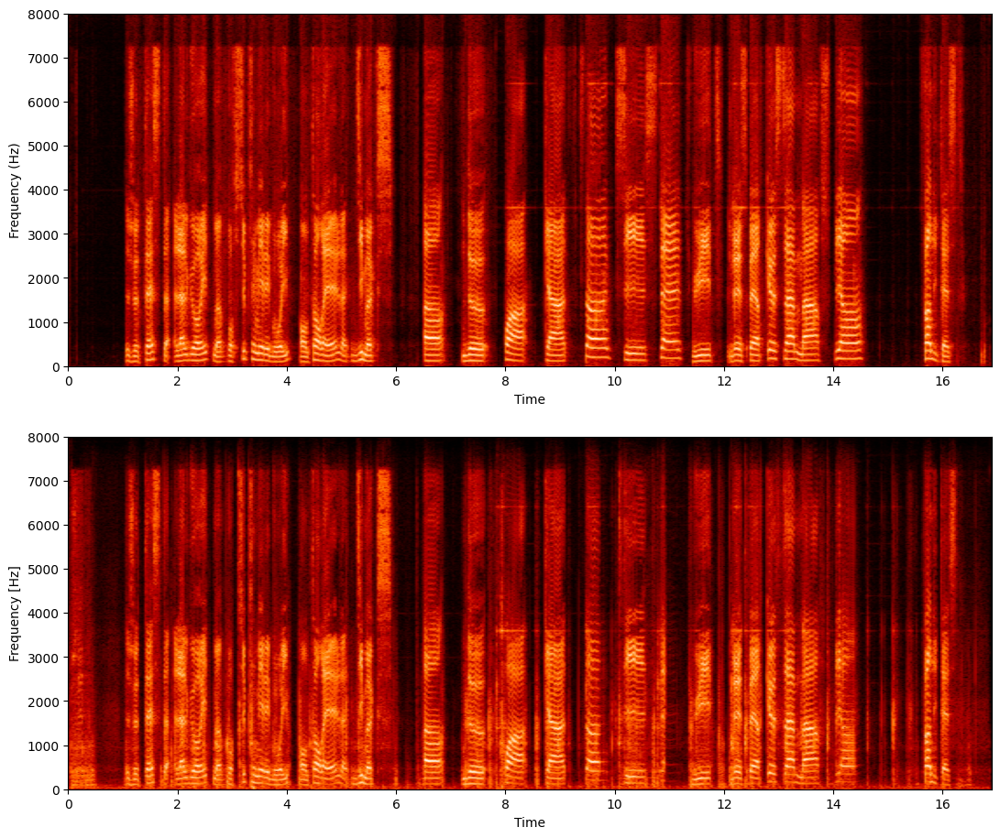

In [10]:
plot_specs(causal_denoised.squeeze().numpy(), nc_denoised.squeeze().numpy())

In [11]:
frame_size = 16 * 40 # 40ms
n_chunks = wav.shape[1] // frame_size

chunked_wav = torch.stack(torch.chunk(wav.squeeze(), n_chunks)[:-1], dim=0)
print(chunked_wav.shape)
with torch.no_grad():
    nc_denoised_chunked = model_nc(chunked_wav)
    causal_denoised_chunked = model(chunked_wav)
disp.display(disp.Audio(causal_denoised_chunked.reshape(-1).numpy(), rate=model.sample_rate))
disp.display(disp.Audio(nc_denoised_chunked.reshape(-1).numpy(), rate=model.sample_rate))

torch.Size([420, 642])


C:\Users\Пользователь\AppData\Local\Temp\ipykernel_11496\117690652.py:11: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at ..\torch\csrc\utils\tensor_numpy.cpp:212.)
  chunks = torch.from_numpy(librosa.util.frame(wav_padded, frame_length=chunk_size, hop_length=stride)).permute(1, 0)


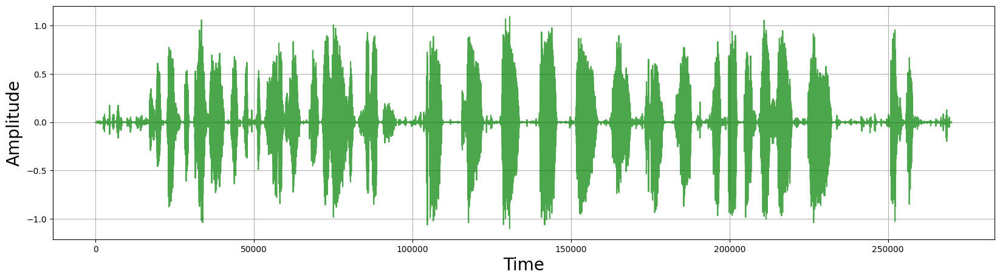

In [12]:
import librosa

def overlap_add(model, wav: np.ndarray, chunk_size):
    stride = chunk_size // 2
    n = len(wav) - chunk_size
    n_chunks = n // stride + 1 + (n % stride > 0)
    n_pad = stride - n % stride

    wav_padded = np.pad(wav, (0, n_pad), 'constant', constant_values=(0, 1e-5))

    chunks = torch.from_numpy(librosa.util.frame(wav_padded, frame_length=chunk_size, hop_length=stride)).permute(1, 0)

    with torch.no_grad():
        chunks = model(chunks)[:, 0, :]

    n_chunks = chunks.shape[0]
    first = chunks[0, 0:stride]
    last = chunks[-1, stride:]

    overlapped_chunks = chunks.reshape(-1)[stride:chunk_size * (n_chunks - 1) + stride].reshape(-1, chunk_size)
    window_vec = torch.sin(torch.arange(stride) / (stride - 1)) * (np.pi / 2)
    kernel_matrix = torch.zeros(2*stride, stride, dtype=overlapped_chunks.dtype)
    kernel_matrix[:stride, :] = torch.diag(1 - window_vec)
    kernel_matrix[stride:, :] = torch.diag(window_vec)
    sum_overlapped_chunks = (overlapped_chunks @ kernel_matrix).reshape(-1)

    overlap_added_wav = torch.cat((first, sum_overlapped_chunks, last), dim=-1)
    return overlap_added_wav

overadd_wav = overlap_add(model, wav.squeeze().numpy(), chunk_size=650)
visualize_audio(overadd_wav, sr)

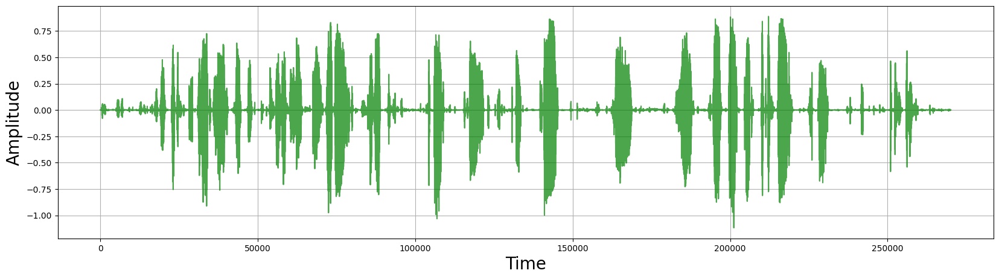

In [13]:
overadd_wav = overlap_add(model_nc, wav.squeeze().numpy(), chunk_size=650)
visualize_audio(overadd_wav, sr)

## Streaming Processing

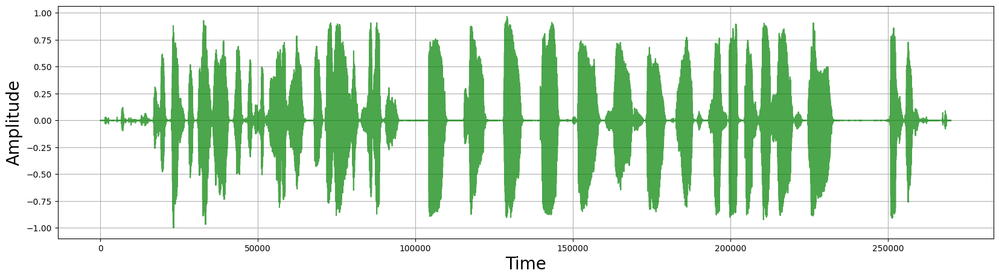

In [14]:
from denoiser.demucs import DemucsStreamer

streamer = DemucsStreamer(model)
with torch.no_grad():
    estimate = torch.cat([
        streamer.feed(wav),
        streamer.flush()], dim=1)[None]

visualize_audio(estimate.squeeze(), sr)

In original demucs implementation there are 3 main techniques to enhance quality on evaluation of real-time model:
- Normalize audio with variance estimated during evaluation;

- Padding with history before upsampling and downsampling;

- Return extra strides from model inference.

In [ ]:
import math
from denoiser.resample import upsample2, downsample2

def demucs_process(model, wav):
    streamer = DemucsStreamer(model)
    resample_buffer = streamer.resample_buffer
    stride = streamer.stride
    resample = model.resample
    n_frames = 0
    total_variance = 0

    resample_in = torch.zeros(1, resample_buffer)
    resample_out = torch.zeros(1, resample_buffer)

    stream = wav
    outs = []
    while stream.shape[1] >= streamer.total_length:
        n_frames += 1
        frame = stream[:, :streamer.total_length]
        if model.normalize:
            mono = frame.mean(0)
            variance = (mono**2).mean()
            total_variance = variance / n_frames + (1 - 1 / n_frames) * total_variance # update variance
            frame = frame / (model.floor + math.sqrt(total_variance)) # norm audio by variance
        padded_frame = torch.cat([resample_in, frame], dim=-1)
        resample_in[:] = frame[:, stride - resample_buffer:stride]
        frame = padded_frame

        if resample == 4:
            frame = upsample2(upsample2(frame))
        elif resample == 2:
            frame = upsample2(frame)
        frame = frame[:, resample * resample_buffer:]  # remove pre sampling buffer
        frame = frame[:, :resample * streamer.frame_length]  # remove extra samples after window

        out, extra = streamer._separate_frame(frame)
        padded_out = torch.cat([resample_out, out, extra], 1)
        resample_out[:] = out[:, -resample_buffer:]
        if resample == 4:
            out = downsample2(downsample2(padded_out))
        elif resample == 2:
            out = downsample2(padded_out)
        else:
            out = padded_out

        out = out[:, resample_buffer // resample:]
        out = out[:, :stride]

        if model.normalize:
            out *= math.sqrt(total_variance)

        outs.append(out)
        stream = stream[:, stride:]

    out = torch.cat(outs, 1)

    return out

In [16]:
with torch.no_grad():
    estimate = demucs_process(model, wav)

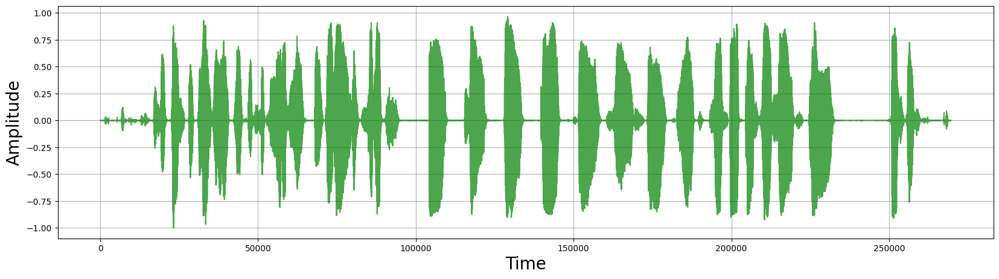

In [17]:
visualize_audio(estimate.squeeze(), sr)

## Complexity estimation

There are certain metrics to compute how suitable you are for realtime setting: they include both model complexity and performance metrics.

* RTF(realtime factor): time of processing of 1 chunk of audio divided by audio length (in seconds)
* Processing time (per second of audio)
* FLOps or MACs: number of arithmetic operations needed to pproduce a result (with input of 1 sec audio)
* Model complexity: number of parameters and/or size in bytes

In [ ]:
#!pip install thop

In [18]:
from thop import profile

def computeGMACandModelSize(model,inputSample,unwrap=False):
    if(unwrap):
        macs, params = profile(model, inputs=(*inputSample,), verbose=False)
    else:
        macs, params = profile(model, inputs=(inputSample,), verbose=False)
    #GFlops = macs * 2.0 / pow(10, 9)#a rough estimate
    GMacs = macs / 1e9
    params_M = params/1e6
    return {"nParameters": params_M, "GMACs": GMacs}

In [19]:
print("SR", sr)
wav1Sec = wav[...,:sr]
print(wav1Sec)

SR 16000
tensor([[-1.8765e-08,  1.0475e-07,  2.1826e-07,  ...,  1.4143e-02,
          1.7293e-02,  2.4121e-02]])


In [20]:
computeGMACandModelSize(model_nc,wav1Sec)

{'nParameters': 60.813953, 'GMACs': 75.560568832}

In [21]:
computeGMACandModelSize(model,wav1Sec)

{'nParameters': 33.533569, 'GMACs': 7.702401024}

Demucs also has a short way to compute delay and RTF on your device:

In [22]:
!python -m denoiser.demucs --hidden=48 --num_threads=4

model size: 72.0MB, delta batch/streaming: 0.50%
initial lag: 41.3ms, stride: 16.0ms
time per frame: 30.2ms, RTF: 1.89
Total lag with computation: 71.5ms


It is given in detail [in the repo](https://github.com/facebookresearch/denoiser/blob/main/denoiser/demucs.py).

## DeepFilterNet overview

[This](https://arxiv.org/pdf/2110.05588) is a DDSP-inspired solution for denoising, it is tested in ``48 kHz``. The code is well-produced, not only on research direction but also nice for applications.

``16 kHz`` is also possible if you do resampling with slight information loss.

In [23]:
from df.enhance import enhance, init_df
import soundfile as sf

c:\Programs\Anaconda3\envs\studyEnv2\lib\site-packages\df\io.py:9: UserWarning: `torchaudio.backend.common.AudioMetaData` has been moved to `torchaudio.AudioMetaData`. Please update the import path.
  from torchaudio.backend.common import AudioMetaData


In [27]:
# Load default model
dfModel, df_state, _ = init_df()

#ORIGINAL
# Download and open some audio file. You use your audio files here
#audio_path = download_file(
#    "https://github.com/Rikorose/DeepFilterNet/raw/e031053/assets/noisy_snr0.wav",
#    download_dir=".",
#)
#audio, sr = sf.read("alex_noisy.mp3")
audio, sr = sf.read("assets_noisy_snr0.wav")

#audio, sr = sf.read("mix5.wav")
audio = torch.from_numpy(audio.astype("float32"))
audio = torchaudio.functional.resample(audio,sr,48000)
print(audio.shape)
# Denoise the audio
enhanced = enhance(dfModel, df_state, audio.unsqueeze(0))
print(enhanced.shape)
# Save for listening
enhanced = torchaudio.functional.resample(enhanced,48000,sr)
#sf.write("enhanced.wav", enhanced.detach().cpu().numpy().T, df_state.sr())
sf.write("enhanced2.wav", enhanced.detach().cpu().numpy().T, sr)

2026-10-22 13:22:46 | INFO     | DF | Loading model settings of DeepFilterNet3
2026-10-22 13:22:46 | INFO     | DF | Using DeepFilterNet3 model at C:\Users\73B5~1\AppData\Local\DeepFilterNet\DeepFilterNet\Cache\DeepFilterNet3
2026-10-22 13:22:46 | INFO     | DF | Initializing model `deepfilternet3`
2026-10-22 13:22:46 | INFO     | DF | Found checkpoint C:\Users\73B5~1\AppData\Local\DeepFilterNet\DeepFilterNet\Cache\DeepFilterNet3\checkpoints\model_120.ckpt.best with epoch 120
2026-10-22 13:22:46 | INFO     | DF | Running on device cpu
2026-10-22 13:22:46 | INFO     | DF | Model loaded
torch.Size([508591])
torch.Size([1, 508591])


In [25]:
#FPS - frame per second
FPS = 100
nb_erb = 32
nb_df =  96
nb_fft_bins = 481
spec = torch.randn(1, 1, FPS, nb_fft_bins, 2)
feat_erb = torch.randn(1, 1, FPS, nb_erb)
feat_spec = torch.randn(1, 1, FPS, nb_df, 2)

inputSample=(spec, feat_erb, feat_spec)
computeGMACandModelSize(dfModel,inputSample, unwrap=True)

{'nParameters': 2.013371, 'GMACs': 0.329472}